In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np

In [3]:
matura_23 = pd.read_excel("data/matura_2023.xlsx")
matura_23 = matura_23.set_index(['Województwo', 'Egzamin']).sort_index()

matura_24 = pd.read_excel("data/matura_2024.xlsx", engine='calamine')
matura_24 = matura_24.set_index(['Wojewodztwo', 'egzamin']).sort_index()

matura_25 = pd.read_excel("data/matura_2025.xlsx", engine='calamine')
matura_25 = matura_25.set_index(['Wojewodztwo', 'egzamin']).sort_index()

matura_26 = pd.read_excel("data/matura_2026.xlsx", engine='calamine')
matura_26 = matura_26.set_index(['Wojewodztwo', 'Egzamin']).sort_index()

maturas = [matura_23, matura_24, matura_25, matura_26]
matura_26

WojewodztwoTeryt  \
Wojewodztwo    Egzamin                                                                
Dolnośląskie   biologia poziom rozszerzony (M)                                    2   
               chemia poziom rozszerzony (M)                                      2   
               filozofia poziom rozszerzony (M)                                   2   
               fizyka poziom rozszerzony (M)                                      2   
               fizyka zestaw zadań w języku angielskim (M)                        2   
...                                                                             ...   
Świętokrzyskie matematyka poziom podstawowy (M)                                  26   
               matematyka poziom rozszerzony (M)                                 26   
               matematyka zestaw zadań w języku angielskim (M)                   26   
               wiedza o społeczeństwie poziom rozszerzony (M19...                26   
               wiedza o społeczeństwie poziom rozszerzony (M22)                  26   

                                                                   LiczbaZdajacych  \
Wojewodztwo    Egzamin                                                               
Dolnośląskie   biologia poziom rozszerzony (M)                                4801   
               chemia poziom rozszerzony (M)                                  2063   
               filozofia poziom rozszerzony (M)                                139   
               fizyka poziom rozszerzony (M)                                  2091   
               fizyka zestaw zadań w języku angielskim (M)                       1   
...                                                                            ...   
Świętokrzyskie matematyka poziom podstawowy (M)                              10246   
               matematyka poziom rozszerzony (M)                              2974   
               matematyka zestaw zadań w języku angielskim (M)                  59   
               wiedza o społeczeństwie poziom rozszerzony (M19...              176   
               wiedza o społeczeństwie poziom rozszerzony (M22)                456   

                                                                   WynikProcentowy  
Wojewodztwo    Egzamin                                                              
Dolnośląskie   biologia poziom rozszerzony (M)                           39.334377  
               chemia poziom rozszerzony (M)                             37.384765  
               filozofia poziom rozszerzony (M)                          32.359712  
               fizyka poziom rozszerzony (M)                             38.354854  
               fizyka zestaw zadań w języku angielskim (M)               16.000000  
...                                                                            ...  
Świętokrzyskie matematyka poziom podstawowy (M)                          61.908017  
               matematyka poziom rozszerzony (M)                         34.861083  
               matematyka zestaw zadań w języku angielskim (M)           55.525424  
               wiedza o społeczeństwie poziom rozszerzony (M19...        25.028409  
               wiedza o społeczeństwie poziom rozszerzony (M22)          43.960526  

[974 rows x 3 columns]

In [4]:
def comp_score_by_years(region: str, subject: str):
  years = [2023, 2024, 2025, 2026]
  scores = []
  for year, matura in zip(years, maturas):
    if year == 2023:
      scores.append(float(matura.loc[(region, subject), 'Średni wynik procentowy']))
    else:
      scores.append(float(matura.loc[(region, subject), 'WynikProcentowy']))
  return years, scores 

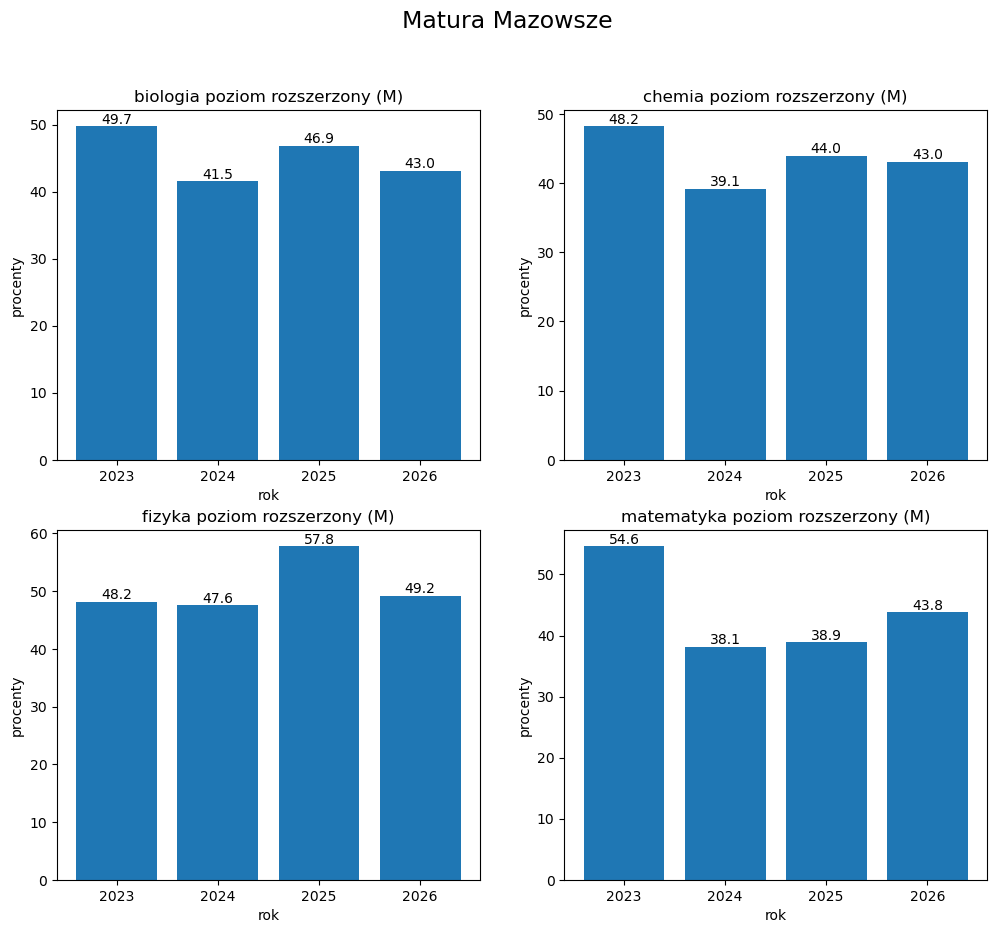

In [5]:
def plot_scores_yearly():
  subjects = ['biologia poziom rozszerzony (M)', 'chemia poziom rozszerzony (M)',
              'fizyka poziom rozszerzony (M)', 'matematyka poziom rozszerzony (M)']
  cols = 2
  rows = math.ceil(len(subjects) / cols)

  fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))
  fig.suptitle(f"Matura Mazowsze", fontsize=17)
  axes = axes.flatten()

  for i, subject in enumerate(subjects):
    ax = axes[i]

    years, scores = comp_score_by_years('Mazowieckie', subject)

    bars = ax.bar(years, scores)
    ax.bar_label(bars, fmt='%.1f')
    ax.set_xticks(years)
    ax.set_title(subject)
    ax.set_xlabel("rok")
    ax.set_ylabel("procenty")

  for j in range(len(subjects), len(axes)):
    fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_scores_yearly()

In [14]:
matura_cent_23 = pd.read_csv('data/matura_centyle_2023.csv', index_col='Subject')
matura_cent_24 = pd.read_csv('data/matura_centyle_2024.csv', index_col='Subject')
matura_cent_25 = pd.read_csv('data/matura_centyle_2025.csv', index_col='Subject')
matura_cent_26 = pd.read_csv('data/matura_centyle_2026.csv', index_col='Subject')
matura_cent_23

,Percentage Score,Centile
Subject,,
Biology (Extended),0,1
Biology (Extended),2,1
Biology (Extended),3,1
Biology (Extended),5,1
Biology (Extended),7,1
...,...,...
Geography (Extended),93,100
Geography (Extended),95,100
Geography (Extended),97,100


In [7]:
matura_cent_23.loc['Biology (Extended)', 'Centile']

Subject
Biology (Extended)      1
Biology (Extended)      1
Biology (Extended)      1
Biology (Extended)      1
Biology (Extended)      1
                     ... 
Biology (Extended)    100
Biology (Extended)    100
Biology (Extended)    100
Biology (Extended)    100
Biology (Extended)    100
Name: Centile, Length: 61, dtype: int64

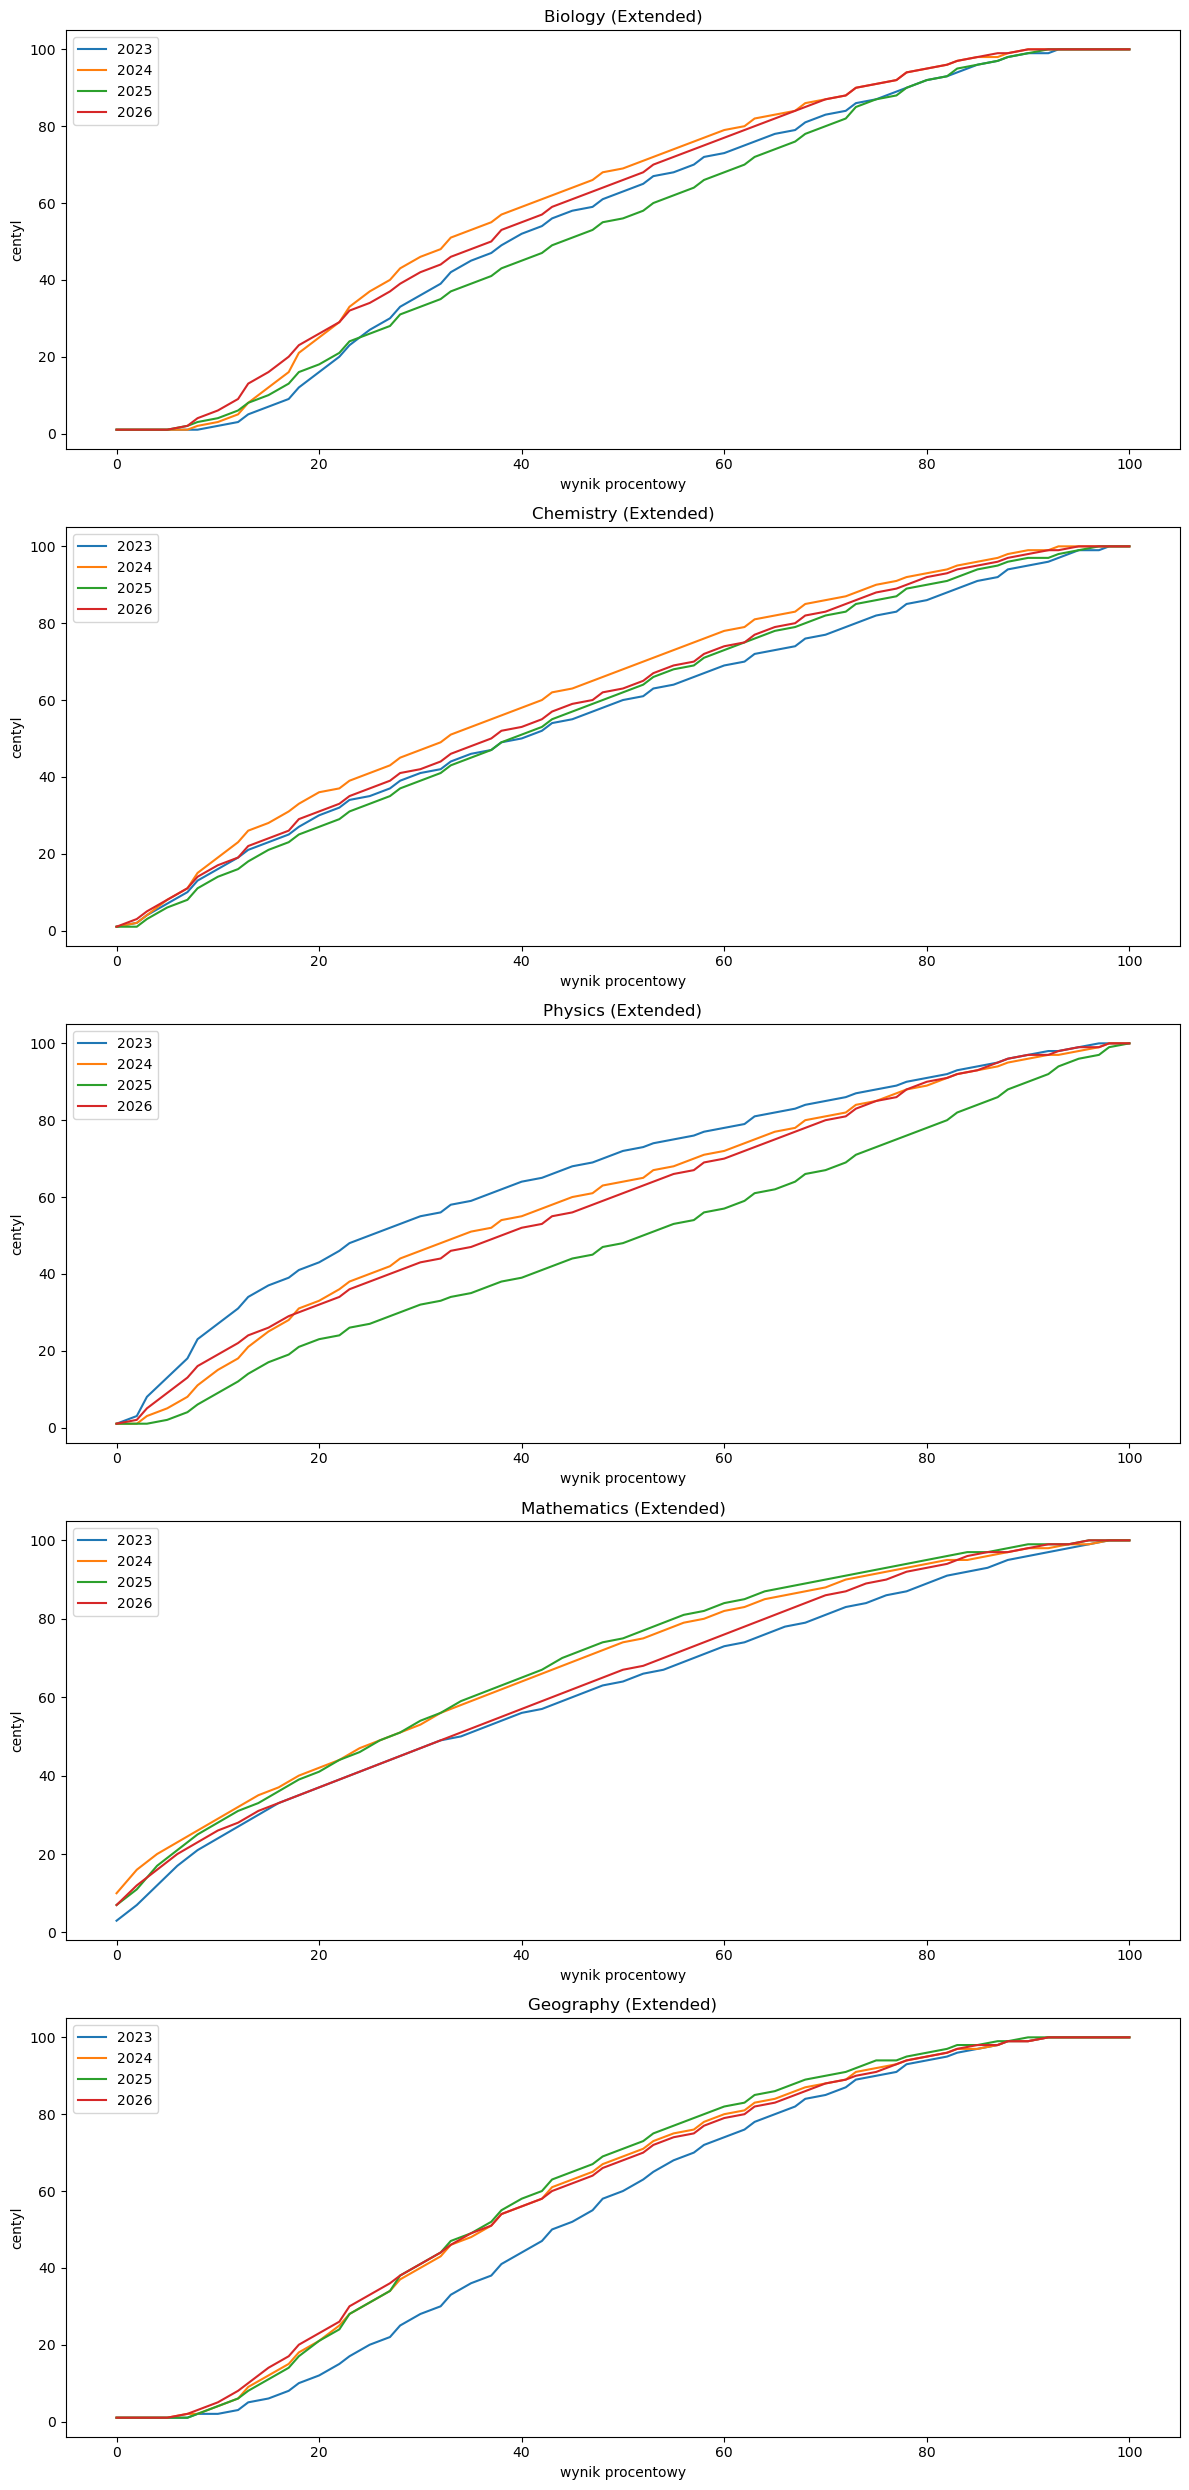

In [15]:
def plot_centiles():
  subjects = ['Biology (Extended)', 'Chemistry (Extended)',
            'Physics (Extended)', 'Mathematics (Extended)', 'Geography (Extended)']
  years = [2023, 2024, 2025, 2026]
  maturas = [matura_cent_23, matura_cent_24, matura_cent_25, matura_cent_26]
  
  cols = 1
  rows = math.ceil(len(subjects) / cols)
  fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))
  
  for i, subject in enumerate(subjects):
    ax = axes[i]
    x_labels = sorted(list(set.union(*[set(m.loc[subject, 'Percentage Score']) for m in maturas])))
    
    for year, matura in zip(years, maturas):
      subject_data = matura.loc[subject].set_index('Percentage Score')
      centiles = [subject_data['Centile'].get(x, np.nan) for x in x_labels]
      
      ax.plot(x_labels, centiles, label=year)
      ax.legend()
      
    ax.set_title(subject)
    ax.set_xlabel("wynik procentowy")
    ax.set_ylabel("centyl")

  plt.tight_layout()
  plt.show()

plot_centiles()